# Câu 5 — Phân phối Monetary và Frequency

Phân tích ở cấp khách hàng từ dữ liệu đơn hàng gốc: loại đơn hủy/hoàn khỏi phân tích chính, tổng hợp Frequency và Monetary, thống kê mô tả, phát hiện outlier bằng IQR, trực quan hóa phân phối và kiểm tra độ nhạy với cách lọc. Các kết luận được sinh từ số liệu thực tế; không cần trạng thái từ notebook khác.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

DATA_PATH = Path("..") / "data" / "cleaned" / "orders_cleaned.csv"
MARTS_DIR = Path("..") / "report"  # bảng CSV tổng hợp
PNG_DIR = Path("..") / "report"  # biểu đồ PNG
MARTS_DIR.mkdir(parents=True, exist_ok=True)
PNG_DIR.mkdir(parents=True, exist_ok=True)
EXCLUDE_STATUS = ["Cancelled", "Returned"]

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print(f"Working directory: {Path.cwd()}")
print(f"Data source: {DATA_PATH} (resolved: {DATA_PATH.resolve()}, exists: {DATA_PATH.is_file()})")
print(f"Output directory: {PNG_DIR.resolve()}")

Working directory: d:\PYTHON\TQHDL\Ecommerce_analysis\notebooks
Data source: ..\data\cleaned\orders_cleaned.csv (resolved: D:\PYTHON\TQHDL\Ecommerce_analysis\data\cleaned\orders_cleaned.csv, exists: True)
Output directory: D:\PYTHON\TQHDL\Ecommerce_analysis\report


## 1. Đọc và kiểm tra dữ liệu

Kiểm tra hình dạng, kiểu dữ liệu, thiếu dữ liệu, tính duy nhất của mã đơn, giá trị tiền hàng và cơ cấu trạng thái trước khi tổng hợp.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy CSV dữ liệu gốc: {DATA_PATH}. Hãy đặt file ở data/cleaned/orders_cleaned.csv.")

orders = pd.read_csv(DATA_PATH)
required_columns = ["order_id", "customer_id", "order_date", "order_status", "returned", "total_amount_usd"]
missing_columns = sorted(set(required_columns) - set(orders.columns))
if missing_columns:
    raise ValueError(f"CSV thiếu các cột bắt buộc: {missing_columns}")

print(f"Shape: {orders.shape[0]:,} dòng × {orders.shape[1]} cột")
display(orders.dtypes.rename("dtype").to_frame())

missing_values = orders[required_columns].isna().sum().rename("missing_count").to_frame()
display(missing_values)
analysis_columns = ["order_id", "customer_id", "order_status", "total_amount_usd"]
if orders[analysis_columns].isna().any().any():
    raise ValueError("Các cột phục vụ lọc/tổng hợp có giá trị thiếu; cần xử lý dữ liệu trước khi phân tích.")

duplicate_order_count = int(orders["order_id"].duplicated().sum())
orders["total_amount_usd"] = pd.to_numeric(orders["total_amount_usd"], errors="coerce")
if orders["total_amount_usd"].isna().any():
    raise ValueError("total_amount_usd có giá trị không chuyển đổi được sang số.")
nonpositive_amount_count = int(orders["total_amount_usd"].le(0).sum())
print(f"Số order_id trùng ngoài lần xuất hiện đầu: {duplicate_order_count:,}")
print(f"Số đơn có total_amount_usd <= 0: {nonpositive_amount_count:,}")

status_counts = orders["order_status"].value_counts(dropna=False).rename_axis("order_status").to_frame("order_count")
status_counts["percentage"] = status_counts["order_count"] / len(orders) * 100
display(status_counts.style.format({"order_count": "{:,.0f}", "percentage": "{:.2f}%"}))
display(Markdown(
    f"**Nhận xét kiểm tra:** Dữ liệu có {len(orders):,} đơn; {int(missing_values['missing_count'].sum()):,} ô thiếu ở 6 cột được kiểm tra, "
    f"{duplicate_order_count:,} order_id trùng và {nonpositive_amount_count:,} đơn có tổng tiền không dương. "
    f"Trạng thái nhiều nhất là {status_counts.index[0]} ({int(status_counts.iloc[0]['order_count']):,} đơn; {status_counts.iloc[0]['percentage']:.2f}%)."
))

Shape: 25,000 dòng × 29 cột


,dtype
order_id,str
customer_id,str
order_date,str
year,int64
month,int64
quarter,str
day_of_week,str
product_name,str
category,str
unit_price_usd,float64


,missing_count
order_id,0
customer_id,0
order_date,0
order_status,0
returned,0
total_amount_usd,0


Số order_id trùng ngoài lần xuất hiện đầu: 0
Số đơn có total_amount_usd <= 0: 0


,order_count,percentage
order_status,,
Delivered,"20,497",81.99%
Returned,"2,020",8.08%
Cancelled,"1,456",5.82%
Processing,"1,027",4.11%


**Nhận xét kiểm tra:** Dữ liệu có 25,000 đơn; 0 ô thiếu ở 6 cột được kiểm tra, 0 order_id trùng và 0 đơn có tổng tiền không dương. Trạng thái nhiều nhất là Delivered (20,497 đơn; 81.99%).

## 2. Lọc đơn hợp lệ cho phân tích chính

Loại `Cancelled` và `Returned` theo yêu cầu vì đơn hủy/đơn hoàn không được tính là doanh thu thực trong phân tích này. Bảng dưới cho thấy quy mô đơn hàng và khách hàng trước/sau lọc.

In [3]:
orders_valid = orders.loc[~orders["order_status"].isin(EXCLUDE_STATUS)].copy()
filter_counts = pd.DataFrame(
    {
        "orders": [len(orders), len(orders_valid)],
        "customers": [orders["customer_id"].nunique(), orders_valid["customer_id"].nunique()],
    },
    index=["Before filtering", "After excluding Cancelled / Returned"],
)
display(filter_counts)
display(Markdown(
    f"**Nhận xét:** Loại {len(orders) - len(orders_valid):,} đơn thuộc trạng thái Cancelled/Returned; "
    f"số khách hàng duy nhất thay đổi từ {orders['customer_id'].nunique():,} xuống "
    f"{orders_valid['customer_id'].nunique():,}. Phân tích chính dùng {len(orders_valid):,} đơn còn lại."
))

,orders,customers
Before filtering,25000,7663
After excluding Cancelled / Returned,21524,7474


**Nhận xét:** Loại 3,476 đơn thuộc trạng thái Cancelled/Returned; số khách hàng duy nhất thay đổi từ 7,663 xuống 7,474. Phân tích chính dùng 21,524 đơn còn lại.

## 3. Tổng hợp ở cấp khách hàng

**Frequency** là số `order_id` khác nhau của khách hàng; **Monetary** là tổng `total_amount_usd` của các đơn sau lọc. Mỗi khách hàng phải tương ứng đúng một dòng.

In [4]:
customer_metrics = (
    orders_valid.groupby("customer_id", as_index=False)
    .agg(Frequency=("order_id", "nunique"), Monetary=("total_amount_usd", "sum"))
)
duplicate_customer_rows = int(customer_metrics["customer_id"].duplicated().sum())
customer_metric_missing = int(customer_metrics[["customer_id", "Frequency", "Monetary"]].isna().sum().sum())
if duplicate_customer_rows != 0 or customer_metric_missing != 0:
    raise AssertionError("Bảng tổng hợp không đảm bảo một dòng/khách hàng hoặc có giá trị thiếu.")
if not customer_metrics["Frequency"].gt(0).all():
    raise AssertionError("Frequency phải là số nguyên dương.")

print(f"Số dòng cấp khách hàng: {len(customer_metrics):,}")
print(f"Số customer_id trùng trong bảng tổng hợp: {duplicate_customer_rows}")
print(f"Số ô thiếu trong các cột tổng hợp: {customer_metric_missing}")
display(customer_metrics.head())
display(Markdown(
    f"**Nhận xét:** Bảng cấp khách hàng có {len(customer_metrics):,} khách hàng; "
    f"mỗi khách hàng có một dòng (trùng {duplicate_customer_rows}) và không thiếu giá trị ở các trường tổng hợp ({customer_metric_missing} ô thiếu)."
))

Số dòng cấp khách hàng: 7,474
Số customer_id trùng trong bảng tổng hợp: 0
Số ô thiếu trong các cột tổng hợp: 0


,customer_id,Frequency,Monetary
0,C00001,2,511.55
1,C00002,2,53.06
2,C00003,3,251.44
3,C00005,4,342.29
4,C00006,3,240.30


**Nhận xét:** Bảng cấp khách hàng có 7,474 khách hàng; mỗi khách hàng có một dòng (trùng 0) và không thiếu giá trị ở các trường tổng hợp (0 ô thiếu).

## 4. Thống kê mô tả

Bảng gồm các thống kê vị trí, độ phân tán, phân vị cao và hình dạng phân phối; bảng được lưu thành CSV trong `report/`.

In [5]:
metric_names = ["Frequency", "Monetary"]
quantiles = customer_metrics[metric_names].quantile([0.25, 0.75, 0.90, 0.95, 0.99])
descriptive_stats = pd.DataFrame(index=metric_names)
for metric in metric_names:
    values = customer_metrics[metric]
    descriptive_stats.loc[metric, "count"] = values.count()
    descriptive_stats.loc[metric, "mean"] = values.mean()
    descriptive_stats.loc[metric, "median"] = values.median()
    descriptive_stats.loc[metric, "std"] = values.std()
    descriptive_stats.loc[metric, "min"] = values.min()
    descriptive_stats.loc[metric, "Q1"] = quantiles.loc[0.25, metric]
    descriptive_stats.loc[metric, "Q3"] = quantiles.loc[0.75, metric]
    descriptive_stats.loc[metric, "P90"] = quantiles.loc[0.90, metric]
    descriptive_stats.loc[metric, "P95"] = quantiles.loc[0.95, metric]
    descriptive_stats.loc[metric, "P99"] = quantiles.loc[0.99, metric]
    descriptive_stats.loc[metric, "max"] = values.max()
    descriptive_stats.loc[metric, "skewness"] = stats.skew(values, bias=False)
    descriptive_stats.loc[metric, "kurtosis"] = stats.kurtosis(values, fisher=True, bias=False)

descriptive_stats["count"] = descriptive_stats["count"].astype(int)
descriptive_stats.to_csv(MARTS_DIR / "q5_descriptive_stats.csv", index_label="metric")
display(descriptive_stats.round(3))
display(Markdown(
    f"**Nhận xét:** Frequency có mean {descriptive_stats.loc['Frequency', 'mean']:.2f}, median "
    f"{descriptive_stats.loc['Frequency', 'median']:.2f}, skewness {descriptive_stats.loc['Frequency', 'skewness']:.2f}; "
    f"Monetary có mean ${descriptive_stats.loc['Monetary', 'mean']:,.2f}, median "
    f"${descriptive_stats.loc['Monetary', 'median']:,.2f}, skewness {descriptive_stats.loc['Monetary', 'skewness']:.2f}. "
    "So sánh mean với median và dấu/độ lớn skewness cho biết mức độ lệch và ảnh hưởng của đuôi phân phối."
))

,count,mean,median,std,min,Q1,Q3,P90,P95,P99,max,skewness,kurtosis
Frequency,7474,2.88,3.000,1.535,1.00,2.000,4.000,5.000,6.000,7.000,10.00,0.852,0.660
Monetary,7474,361.96,277.885,314.476,8.61,140.172,480.638,764.885,985.797,1457.142,3602.81,2.025,7.067


**Nhận xét:** Frequency có mean 2.88, median 3.00, skewness 0.85; Monetary có mean $361.96, median $277.88, skewness 2.02. So sánh mean với median và dấu/độ lớn skewness cho biết mức độ lệch và ảnh hưởng của đuôi phân phối.

## 5. Bảng phân bố Frequency

Bảng thể hiện số khách hàng ở mỗi tần suất mua, tỷ trọng và tỷ trọng tích lũy; được lưu thành CSV.

In [6]:
frequency_distribution = (
    customer_metrics["Frequency"].value_counts().sort_index().rename_axis("Frequency").to_frame("customer_count")
)
frequency_distribution["percentage"] = frequency_distribution["customer_count"] / len(customer_metrics) * 100
frequency_distribution["cumulative_percentage"] = frequency_distribution["percentage"].cumsum()
frequency_distribution.to_csv(MARTS_DIR / "q5_frequency_distribution.csv")
display(frequency_distribution.round(2))
frequency_mode = int(frequency_distribution["customer_count"].idxmax())
mode_customer_pct = float(frequency_distribution.loc[frequency_mode, "percentage"])
display(Markdown(
    f"**Nhận xét:** Mức Frequency phổ biến nhất là {frequency_mode} đơn/khách, gồm "
    f"{frequency_distribution.loc[frequency_mode, 'customer_count']:,} khách ({mode_customer_pct:.2f}%). "
    f"Bảng phân bố bao phủ {frequency_distribution.index.min()}–{frequency_distribution.index.max()} đơn/khách; "
    "tỷ lệ tích lũy cho biết phần khách hàng đạt đến từng mức Frequency."
))

,customer_count,percentage,cumulative_percentage
Frequency,,,
1,1482,19.83,19.83
2,2002,26.79,46.61
3,1722,23.04,69.65
4,1168,15.63,85.28
5,644,8.62,93.90
6,293,3.92,97.82
7,105,1.40,99.22
8,41,0.55,99.77
9,11,0.15,99.92


**Nhận xét:** Mức Frequency phổ biến nhất là 2 đơn/khách, gồm 2,002 khách (26.79%). Bảng phân bố bao phủ 1–10 đơn/khách; tỷ lệ tích lũy cho biết phần khách hàng đạt đến từng mức Frequency.

## 5.1. Median nội suy cho Frequency (biến đếm rời rạc)

Frequency nhận giá trị nguyên nên median rời rạc có thể trùng một mức cụ thể. Median nội suy ước lượng vị trí 50% bên trong khoảng của mức chứa median.

In [7]:
freq_counts = customer_metrics["Frequency"].value_counts().sort_index()
n_customers = int(freq_counts.sum())
frequency_mean = customer_metrics["Frequency"].mean()
frequency_median = customer_metrics["Frequency"].median()
cum_counts = freq_counts.cumsum()

median_class = int(cum_counts[cum_counts >= n_customers / 2].index[0])
cum_before = int(cum_counts.loc[median_class] - freq_counts.loc[median_class])
class_count = int(freq_counts.loc[median_class])
interp_median = (median_class - 0.5) + (n_customers / 2 - cum_before) / class_count

high_freq_threshold = 6
high_freq_pct = customer_metrics["Frequency"].ge(high_freq_threshold).mean() * 100

freq_center = pd.DataFrame(
    {"value": [frequency_mode, customer_metrics["Frequency"].median(), interp_median, frequency_mean]},
    index=["Mode", "Median (rời rạc)", "Median (nội suy)", "Mean"],
)
display(freq_center.round(3))

order_text = "mean > median nội suy" if frequency_mean > interp_median else "mean <= median nội suy"
display(Markdown(
    f"**Nhận xét:** Median rời rạc = {customer_metrics['Frequency'].median():.0f} là mức trung vị theo bậc nguyên; "
    f"{cum_before / n_customers * 100:.2f}% khách có Frequency ≤ {median_class - 1}, nên median nội suy = **{interp_median:.2f}**. "
    f"So với mean = {frequency_mean:.2f} ta có **{order_text}**, phù hợp với skewness "
    f"{descriptive_stats.loc['Frequency', 'skewness']:.2f} > 0. "
    f"Mức lệch phải của Frequency chủ yếu đến từ nhóm {high_freq_pct:.2f}% khách có ≥ {high_freq_threshold} đơn, "
    "không phải đuôi dài như Monetary."
))

,value
Mode,2.000
Median (rời rạc),3.000
Median (nội suy),2.647
Mean,2.880


**Nhận xét:** Median rời rạc = 3 là mức trung vị theo bậc nguyên; 46.61% khách có Frequency ≤ 2, nên median nội suy = **2.65**. So với mean = 2.88 ta có **mean > median nội suy**, phù hợp với skewness 0.85 > 0. Mức lệch phải của Frequency chủ yếu đến từ nhóm 6.10% khách có ≥ 6 đơn, không phải đuôi dài như Monetary.

## 6. Phát hiện outlier theo IQR

Ngưỡng trên được tính là `Q3 + 1.5 × IQR`; các giá trị lớn hơn ngưỡng được đếm là outlier.

In [8]:
outlier_rows = []
for metric in metric_names:
    q1 = customer_metrics[metric].quantile(0.25)
    q3 = customer_metrics[metric].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    outlier_count = int(customer_metrics[metric].gt(upper_bound).sum())
    outlier_rows.append({
        "metric": metric,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "upper_threshold": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": outlier_count / len(customer_metrics) * 100,
    })
outlier_summary = pd.DataFrame(outlier_rows).set_index("metric")
outlier_summary.to_csv(MARTS_DIR / "q5_outlier_summary.csv")
display(outlier_summary.round(3))
display(Markdown(
    f"**Nhận xét:** Theo ngưỡng trên IQR, Frequency có {outlier_summary.loc['Frequency', 'outlier_count']:,} outlier "
    f"({outlier_summary.loc['Frequency', 'outlier_percentage']:.2f}%), Monetary có "
    f"{outlier_summary.loc['Monetary', 'outlier_count']:,} outlier "
    f"({outlier_summary.loc['Monetary', 'outlier_percentage']:.2f}%). Đây là các giá trị ở phía trên ngưỡng Q3 + 1.5×IQR."
))

,Q1,Q3,IQR,upper_threshold,outlier_count,outlier_percentage
metric,,,,,,
Frequency,2.000,4.000,2.000,7.000,58,0.776
Monetary,140.172,480.638,340.465,991.335,369,4.937


**Nhận xét:** Theo ngưỡng trên IQR, Frequency có 58 outlier (0.78%), Monetary có 369 outlier (4.94%). Đây là các giá trị ở phía trên ngưỡng Q3 + 1.5×IQR.

## 6.1. Phân tích nhóm outlier Monetary và mức đóng góp doanh thu

Phân tích hồ sơ khách vượt ngưỡng IQR, nguồn gốc outlier và mức tập trung doanh thu.

,customers,revenue,mean_monetary,median_frequency,mean_frequency,median_aov,customer_pct,revenue_pct
is_monetary_outlier,,,,,,,,
Không outlier,7105,2226769.58,313.41,3.0,2.78,96.48,95.06,82.31
Outlier (trên ngưỡng IQR),369,478515.80,1296.79,5.0,4.77,267.83,4.94,17.69


,customers,pct_of_outliers
Chủ yếu đơn giá trị lớn,175,47.43
Cả tần suất và giá trị đơn cao,173,46.88
Chủ yếu mua nhiều đơn,21,5.69


,revenue_share_pct
top_customer_pct,
1,5.03
5,17.87
10,29.83
20,47.62


**Nhận xét:** 369 khách outlier (4.94% khách) đóng góp **17.69%** doanh thu; Monetary trung bình của họ là $1,296.79 so với $313.41 ở nhóm còn lại. Median Frequency của nhóm outlier là 5 (nhóm còn lại: 3); nguyên nhân phổ biến nhất: *Chủ yếu đơn giá trị lớn* (47.4% nhóm outlier). Top 5% khách chiếm 17.87% doanh thu. Khi tính IQR trên log1p(Monetary), có 2 khách vượt ngưỡng trên và 87 khách dưới ngưỡng dưới (so với 369 trên thang gốc). Cách xếp loại outlier thay đổi theo thang biến đổi; kết luận có nên giữ nhóm cần căn cứ vào đóng góp doanh thu và mục tiêu RFM, không kết luận duy nhất chỉ từ skewness.

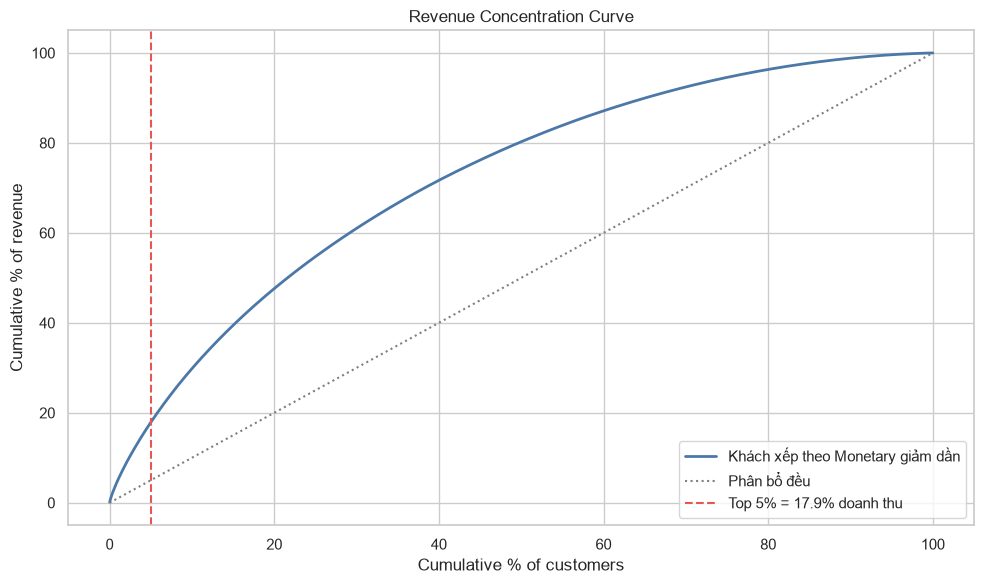

Kiểm tra revenue_pct: 100.000000%
Kiểm tra số khách Monetary outlier: 369 = 369


In [9]:
cm = customer_metrics.copy()
monetary_upper = float(outlier_summary.loc["Monetary", "upper_threshold"])
cm["is_monetary_outlier"] = cm["Monetary"] > monetary_upper
cm["AOV"] = cm["Monetary"] / cm["Frequency"]
total_revenue = cm["Monetary"].sum()

group_profile = cm.groupby("is_monetary_outlier").agg(
    customers=("customer_id", "count"),
    revenue=("Monetary", "sum"),
    mean_monetary=("Monetary", "mean"),
    median_frequency=("Frequency", "median"),
    mean_frequency=("Frequency", "mean"),
    median_aov=("AOV", "median"),
)
group_profile["customer_pct"] = group_profile["customers"] / len(cm) * 100
group_profile["revenue_pct"] = group_profile["revenue"] / total_revenue * 100
group_profile.index = group_profile.index.map({False: "Không outlier", True: "Outlier (trên ngưỡng IQR)"})
display(group_profile.round(2))

outlier_cm = cm[cm["is_monetary_outlier"]]
high_freq_cut = cm["Frequency"].quantile(0.75)
aov_cut = cm["AOV"].quantile(0.75)
driver = pd.Series(
    np.select(
        [
            (outlier_cm["Frequency"] > high_freq_cut) & (outlier_cm["AOV"] > aov_cut),
            outlier_cm["Frequency"] > high_freq_cut,
            outlier_cm["AOV"] > aov_cut,
        ],
        ["Cả tần suất và giá trị đơn cao", "Chủ yếu mua nhiều đơn", "Chủ yếu đơn giá trị lớn"],
        default="Khác",
    ),
    index=outlier_cm.index,
)
driver_table = driver.value_counts().rename("customers").to_frame()
driver_table["pct_of_outliers"] = driver_table["customers"] / len(outlier_cm) * 100
display(driver_table.round(2))

sorted_rev = cm["Monetary"].sort_values(ascending=False).reset_index(drop=True)
concentration = pd.DataFrame(
    {
        "top_customer_pct": [1, 5, 10, 20],
        "revenue_share_pct": [
            sorted_rev.head(max(int(np.ceil(len(cm) * p / 100)), 1)).sum() / total_revenue * 100
            for p in [1, 5, 10, 20]
        ],
    }
).set_index("top_customer_pct")
display(concentration.round(2))

log_m = np.log1p(cm["Monetary"])
lq1, lq3 = log_m.quantile([0.25, 0.75])
log_upper = lq3 + 1.5 * (lq3 - lq1)
log_lower = lq1 - 1.5 * (lq3 - lq1)
log_high = int((log_m > log_upper).sum())
log_low = int((log_m < log_lower).sum())

group_profile.to_csv(MARTS_DIR / "q5_monetary_outlier_profile.csv", index_label="group")
concentration.to_csv(MARTS_DIR / "q5_revenue_concentration.csv")

out_row = group_profile.loc["Outlier (trên ngưỡng IQR)"]
non_row = group_profile.loc["Không outlier"]
top_driver = driver_table.index[0]
display(Markdown(
    f"**Nhận xét:** {int(out_row['customers']):,} khách outlier ({out_row['customer_pct']:.2f}% khách) đóng góp "
    f"**{out_row['revenue_pct']:.2f}%** doanh thu; Monetary trung bình của họ là ${out_row['mean_monetary']:,.2f} "
    f"so với ${non_row['mean_monetary']:,.2f} ở nhóm còn lại. Median Frequency của nhóm outlier là "
    f"{out_row['median_frequency']:.0f} (nhóm còn lại: {non_row['median_frequency']:.0f}); "
    f"nguyên nhân phổ biến nhất: *{top_driver}* ({driver_table.iloc[0]['pct_of_outliers']:.1f}% nhóm outlier). "
    f"Top 5% khách chiếm {concentration.loc[5, 'revenue_share_pct']:.2f}% doanh thu. "
    f"Khi tính IQR trên log1p(Monetary), có {log_high:,} khách vượt ngưỡng trên và {log_low:,} khách dưới ngưỡng dưới "
    f"(so với {int(outlier_summary.loc['Monetary', 'outlier_count']):,} trên thang gốc). "
    "Cách xếp loại outlier thay đổi theo thang biến đổi; kết luận có nên giữ nhóm cần căn cứ vào đóng góp doanh thu và mục tiêu RFM, "
    "không kết luận duy nhất chỉ từ skewness."
))

cum_customer = np.arange(1, len(sorted_rev) + 1) / len(sorted_rev) * 100
cum_revenue = sorted_rev.cumsum() / total_revenue * 100
fig, ax = plt.subplots()
ax.plot(cum_customer, cum_revenue, color="#4C78A8", linewidth=2, label="Khách xếp theo Monetary giảm dần")
ax.plot([0, 100], [0, 100], color="gray", linestyle=":", label="Phân bổ đều")
ax.axvline(5, color="#E45756", linestyle="--", label=f"Top 5% = {concentration.loc[5, 'revenue_share_pct']:.1f}% doanh thu")
ax.set(title="Revenue Concentration Curve", xlabel="Cumulative % of customers", ylabel="Cumulative % of revenue")
ax.legend()
fig.tight_layout()
fig.savefig(PNG_DIR / "q5_revenue_concentration.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

revenue_pct_sum = float(group_profile["revenue_pct"].sum())
monetary_outlier_count = int(out_row["customers"])
assert abs(revenue_pct_sum - 100.0) < 1e-6
assert monetary_outlier_count == int(outlier_summary.loc["Monetary", "outlier_count"])
print(f"Kiểm tra revenue_pct: {revenue_pct_sum:.6f}%")
print(f"Kiểm tra số khách Monetary outlier: {monetary_outlier_count:,} = {int(outlier_summary.loc['Monetary', 'outlier_count']):,}")


## 7. Histogram

Histogram Frequency dùng bins căn giữa số nguyên; Monetary có KDE; biểu đồ log dùng `log1p` để quan sát phần thân phân phối. Tất cả biểu đồ được lưu PNG ở độ phân giải 150 dpi.

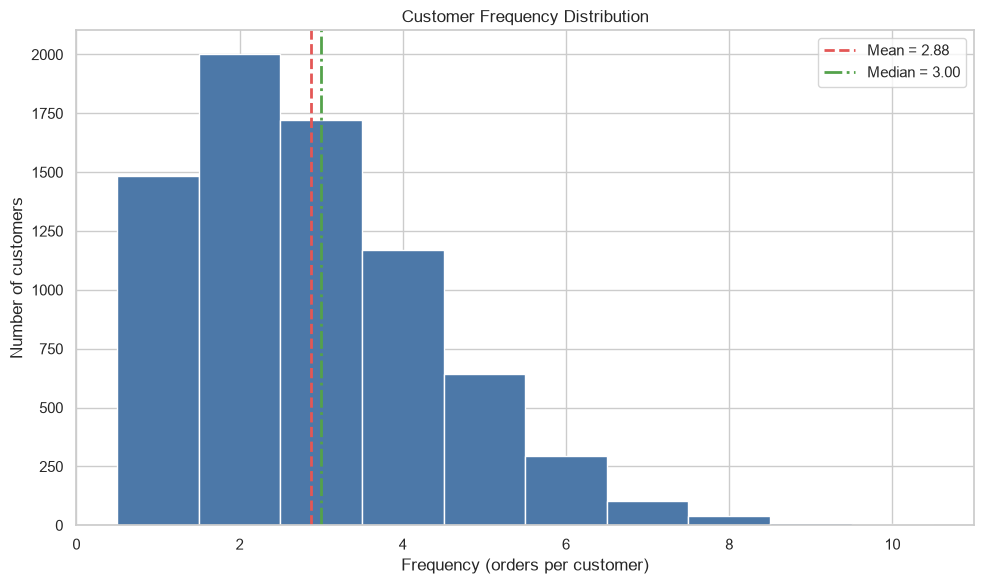

**Biểu đồ Frequency:** Cột cao nhất ở mức 2 đơn/khách (26.79% khách); mean = 2.88, median = 3.00, skewness = 0.85.

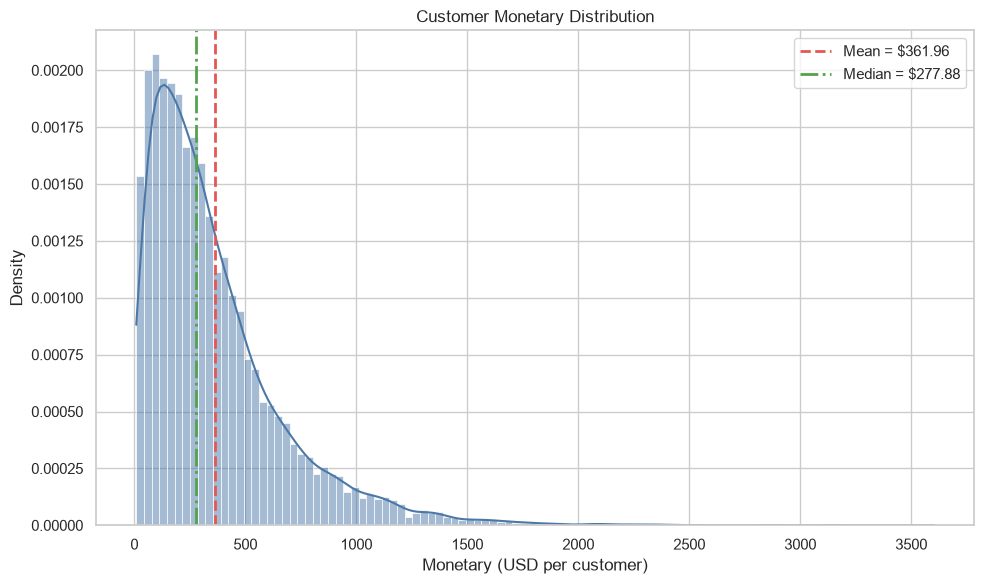

**Biểu đồ Monetary:** Khoảng có cột cao nhất xấp xỉ $77.73–$112.29; mean = $361.96, median = $277.88, skewness = 2.02.

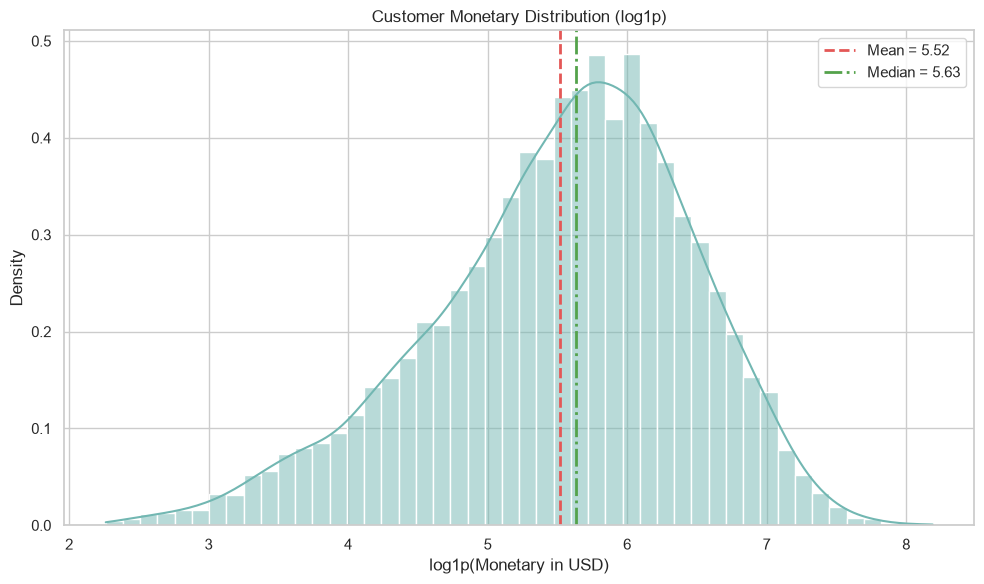

**Biểu đồ log1p(Monetary):** Sau biến đổi, mean = 5.52, median = 5.63, skewness = -0.52; so sánh với biểu đồ USD gốc để đánh giá độ co của đuôi phải.

In [10]:
frequency_mean = customer_metrics["Frequency"].mean()
frequency_median = customer_metrics["Frequency"].median()
frequency_edges = np.arange(customer_metrics["Frequency"].min() - 0.5, customer_metrics["Frequency"].max() + 1.5, 1)
fig, ax = plt.subplots()
ax.hist(customer_metrics["Frequency"], bins=frequency_edges, color="#4C78A8", edgecolor="white")
ax.axvline(frequency_mean, color="#E45756", linestyle="--", linewidth=2, label=f"Mean = {frequency_mean:.2f}")
ax.axvline(frequency_median, color="#54A24B", linestyle="-.", linewidth=2, label=f"Median = {frequency_median:.2f}")
ax.set(title="Customer Frequency Distribution", xlabel="Frequency (orders per customer)", ylabel="Number of customers")
ax.legend()
fig.tight_layout()
fig.savefig(PNG_DIR / "q5_hist_frequency.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
display(Markdown(
    f"**Biểu đồ Frequency:** Cột cao nhất ở mức {frequency_mode} đơn/khách ({mode_customer_pct:.2f}% khách); "
    f"mean = {frequency_mean:.2f}, median = {frequency_median:.2f}, skewness = {descriptive_stats.loc['Frequency', 'skewness']:.2f}."
))

monetary_mean = customer_metrics["Monetary"].mean()
monetary_median = customer_metrics["Monetary"].median()
fig, ax = plt.subplots()
sns.histplot(customer_metrics["Monetary"], bins="auto", kde=True, stat="density", color="#4C78A8", ax=ax)
ax.axvline(monetary_mean, color="#E45756", linestyle="--", linewidth=2, label=f"Mean = ${monetary_mean:,.2f}")
ax.axvline(monetary_median, color="#54A24B", linestyle="-.", linewidth=2, label=f"Median = ${monetary_median:,.2f}")
ax.set(title="Customer Monetary Distribution", xlabel="Monetary (USD per customer)", ylabel="Density")
ax.legend()
fig.tight_layout()
fig.savefig(PNG_DIR / "q5_hist_monetary.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
hist_counts, hist_edges = np.histogram(customer_metrics["Monetary"], bins="auto")
peak_bin = int(np.argmax(hist_counts))
peak_interval = (hist_edges[peak_bin], hist_edges[peak_bin + 1])
display(Markdown(
    f"**Biểu đồ Monetary:** Khoảng có cột cao nhất xấp xỉ ${peak_interval[0]:,.2f}–${peak_interval[1]:,.2f}; "
    f"mean = ${monetary_mean:,.2f}, median = ${monetary_median:,.2f}, skewness = {descriptive_stats.loc['Monetary', 'skewness']:.2f}."
))

monetary_log = np.log1p(customer_metrics["Monetary"])
log_mean = monetary_log.mean()
log_median = monetary_log.median()
fig, ax = plt.subplots()
sns.histplot(monetary_log, bins="auto", kde=True, stat="density", color="#72B7B2", ax=ax)
ax.axvline(log_mean, color="#E45756", linestyle="--", linewidth=2, label=f"Mean = {log_mean:.2f}")
ax.axvline(log_median, color="#54A24B", linestyle="-.", linewidth=2, label=f"Median = {log_median:.2f}")
ax.set(title="Customer Monetary Distribution (log1p)", xlabel="log1p(Monetary in USD)", ylabel="Density")
ax.legend()
fig.tight_layout()
fig.savefig(PNG_DIR / "q5_hist_monetary_log.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
display(Markdown(
    f"**Biểu đồ log1p(Monetary):** Sau biến đổi, mean = {log_mean:.2f}, median = {log_median:.2f}, "
    f"skewness = {stats.skew(monetary_log, bias=False):.2f}; so sánh với biểu đồ USD gốc để đánh giá độ co của đuôi phải."
))

## 8. Phân tích độ nhạy theo cách lọc

So sánh thống kê của cả ba cách: giữ mọi đơn, loại Cancelled / Returned, và chỉ giữ Delivered. Việc so sánh skewness cho biết nhận định về hướng lệch có đổi theo cách lọc hay không.

In [11]:
sensitivity_sets = {
    "All orders": orders,
    "Exclude Cancelled / Returned": orders_valid,
    "Delivered only": orders.loc[orders["order_status"].eq("Delivered")].copy(),
}
sensitivity_rows = []
for filter_name, source in sensitivity_sets.items():
    aggregated = source.groupby("customer_id").agg(
        Frequency=("order_id", "nunique"),
        Monetary=("total_amount_usd", "sum"),
    )
    for metric in metric_names:
        values = aggregated[metric]
        sensitivity_rows.append({
            "filter_method": filter_name,
            "metric": metric,
            "mean": values.mean(),
            "median": values.median(),
            "skewness": stats.skew(values, bias=False),
        })
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(3))
shape_results = {}
for metric in metric_names:
    skews = sensitivity.loc[sensitivity["metric"].eq(metric), "skewness"]
    if (skews > 0).all():
        shape_result = "skewness dương ở cả ba cách lọc"
    elif (skews < 0).all():
        shape_result = "skewness âm ở cả ba cách lọc"
    else:
        shape_result = "dấu skewness thay đổi giữa các cách lọc"
    shape_results[metric] = shape_result
    print(f"{metric}: {shape_result}; skewness theo thứ tự bảng = {', '.join(f'{v:.2f}' for v in skews)}.")
freq_skew_values = sensitivity.loc[sensitivity["metric"].eq("Frequency"), "skewness"]
mon_skew_values = sensitivity.loc[sensitivity["metric"].eq("Monetary"), "skewness"]
freq_direction_changed = not ((freq_skew_values > 0).all() or (freq_skew_values < 0).all() or (freq_skew_values == 0).all())
mon_direction_changed = not ((mon_skew_values > 0).all() or (mon_skew_values < 0).all() or (mon_skew_values == 0).all())
direction_text = (
    "hướng lệch thay đổi" if freq_direction_changed or mon_direction_changed
    else "hướng lệch không đổi"
)
display(Markdown(
    f"**Nhận xét:** Mean, median và skewness được đối chiếu trực tiếp theo từng cách lọc ở bảng. "
    f"Frequency: {shape_results['Frequency']}, với skewness lần lượt "
    f"{', '.join(f'{v:.2f}' for v in freq_skew_values)}; "
    f"Monetary: {shape_results['Monetary']}, với skewness lần lượt "
    f"{', '.join(f'{v:.2f}' for v in mon_skew_values)}. Do đó, {direction_text} theo ba phương án lọc."
))

,filter_method,metric,mean,median,skewness
0,All orders,Frequency,3.262,3.000,0.747
1,All orders,Monetary,409.292,322.370,1.842
2,Exclude Cancelled / Returned,Frequency,2.880,3.000,0.852
3,Exclude Cancelled / Returned,Monetary,361.960,277.885,2.025
4,Delivered only,Frequency,2.769,3.000,0.872
5,Delivered only,Monetary,349.294,266.300,2.087


Frequency: skewness dương ở cả ba cách lọc; skewness theo thứ tự bảng = 0.75, 0.85, 0.87.
Monetary: skewness dương ở cả ba cách lọc; skewness theo thứ tự bảng = 1.84, 2.02, 2.09.


**Nhận xét:** Mean, median và skewness được đối chiếu trực tiếp theo từng cách lọc ở bảng. Frequency: skewness dương ở cả ba cách lọc, với skewness lần lượt 0.75, 0.85, 0.87; Monetary: skewness dương ở cả ba cách lọc, với skewness lần lượt 1.84, 2.02, 2.09. Do đó, hướng lệch không đổi theo ba phương án lọc.

In [12]:
expected_outputs = [
    "q5_descriptive_stats.csv",
    "q5_frequency_distribution.csv",
    "q5_outlier_summary.csv",
    "q5_hist_frequency.png",
    "q5_hist_monetary.png",
    "q5_hist_monetary_log.png",
    "q5_monetary_outlier_profile.csv",
    "q5_revenue_concentration.csv",
    "q5_revenue_concentration.png",
]
def output_path(filename):
    return (PNG_DIR if filename.endswith(".png") else MARTS_DIR) / filename

output_check = pd.DataFrame({
    "file": expected_outputs,
    "exists": [output_path(filename).is_file() for filename in expected_outputs],
    "bytes": [output_path(filename).stat().st_size if output_path(filename).is_file() else 0 for filename in expected_outputs],
})
display(output_check)
display(Markdown(f"**Kiểm tra xuất file:** {int(output_check['exists'].sum())} trên {len(expected_outputs)} file yêu cầu đã được tạo; CSV nằm trong `{MARTS_DIR}`, PNG nằm trong `{PNG_DIR}`."))
if not output_check["exists"].all() or output_check["bytes"].eq(0).any():
    raise AssertionError("Một hoặc nhiều file kết quả chưa được tạo thành công.")

,file,exists,bytes
0,q5_descriptive_stats.csv,True,377
1,q5_frequency_distribution.csv,True,483
2,q5_outlier_summary.csv,True,181
3,q5_hist_frequency.png,True,48092
4,q5_hist_monetary.png,True,71945
5,q5_hist_monetary_log.png,True,72352
6,q5_monetary_outlier_profile.csv,True,363
7,q5_revenue_concentration.csv,True,123
8,q5_revenue_concentration.png,True,84191


**Kiểm tra xuất file:** 9 trên 9 file yêu cầu đã được tạo; CSV nằm trong `..\report`, PNG nằm trong `..\report`.

## 9. Nhận xét và kết luận

Kết luận sau đây được tạo từ các bảng đã tính ở trên.

In [13]:
frequency_skew = descriptive_stats.loc["Frequency", "skewness"]
monetary_skew = descriptive_stats.loc["Monetary", "skewness"]
frequency_shape = "lệch phải" if frequency_skew > 0 else ("lệch trái" if frequency_skew < 0 else "gần đối xứng")
monetary_shape = "lệch phải" if monetary_skew > 0 else ("lệch trái" if monetary_skew < 0 else "gần đối xứng")
frequency_outliers = int(outlier_summary.loc["Frequency", "outlier_count"])
frequency_outlier_pct = outlier_summary.loc["Frequency", "outlier_percentage"]
monetary_outliers = int(outlier_summary.loc["Monetary", "outlier_count"])
monetary_outlier_pct = outlier_summary.loc["Monetary", "outlier_percentage"]
frequency_gap = frequency_mean - frequency_median
monetary_gap = monetary_mean - monetary_median

conclusion = f"""
### Kết luận từ dữ liệu

- **Frequency:** Phân phối {frequency_shape}, skewness **{frequency_skew:.2f}**; mức phổ biến nhất là **{frequency_mode} đơn/khách** ({mode_customer_pct:.2f}% khách). Mean **{frequency_mean:.2f}** so với median **{frequency_median:.2f}** (chênh mean–median **{frequency_gap:.2f}** đơn); mean là trung bình số học, median là giá trị trung tâm, còn skewness dương thể hiện đuôi phải dài hơn.
- **Monetary:** Phân phối {monetary_shape}, skewness **{monetary_skew:.2f}**; khoảng có histogram cao nhất xấp xỉ **${peak_interval[0]:,.2f}–${peak_interval[1]:,.2f}**. Mean **${monetary_mean:,.2f}** so với median **${monetary_median:,.2f}** (chênh **${monetary_gap:,.2f}**), cho thấy các giá trị đuôi {'nâng' if monetary_gap > 0 else 'hạ'} trung bình so với trung vị.
- **Median nội suy Frequency:** Median rời rạc **{customer_metrics['Frequency'].median():.0f}**; median nội suy là **{interp_median:.2f}**, so với mean **{frequency_mean:.2f}** (**{order_text}**).
- **Outlier Monetary:** Nhóm outlier chiếm **{out_row['customer_pct']:.2f}%** khách và đóng góp **{out_row['revenue_pct']:.2f}%** doanh thu; top 5% khách chiếm **{concentration.loc[5, 'revenue_share_pct']:.2f}%** doanh thu.
- **Outlier IQR:** Frequency có **{frequency_outliers:,} ({frequency_outlier_pct:.2f}%)** giá trị vượt ngưỡng trên; Monetary có **{monetary_outliers:,} ({monetary_outlier_pct:.2f}%)**. Đây là quan sát ở đuôi phải theo quy tắc ngưỡng Q3 + 1.5×IQR, không đồng nghĩa dữ liệu sai.
- **Hàm ý cho RFM:** Monetary gốc có skewness {monetary_skew:.2f}; sau `log1p`, skewness là {stats.skew(monetary_log, bias=False):.2f}. Biến đổi này làm thay đổi hình dạng phân phối trong dữ liệu hiện có. Có thể cân nhắc `log1p` cho Monetary hoặc chia nhóm theo phân vị khi chấm điểm; nên kiểm tra phân phối sau biến đổi trước khi chọn phương pháp.
"""
display(Markdown(conclusion))


### Kết luận từ dữ liệu

- **Frequency:** Phân phối lệch phải, skewness **0.85**; mức phổ biến nhất là **2 đơn/khách** (26.79% khách). Mean **2.88** so với median **3.00** (chênh mean–median **-0.12** đơn); mean là trung bình số học, median là giá trị trung tâm, còn skewness dương thể hiện đuôi phải dài hơn.
- **Monetary:** Phân phối lệch phải, skewness **2.02**; khoảng có histogram cao nhất xấp xỉ **$77.73–$112.29**. Mean **$361.96** so với median **$277.88** (chênh **$84.07**), cho thấy các giá trị đuôi nâng trung bình so với trung vị.
- **Median nội suy Frequency:** Median rời rạc **3**; median nội suy là **2.65**, so với mean **2.88** (**mean > median nội suy**).
- **Outlier Monetary:** Nhóm outlier chiếm **4.94%** khách và đóng góp **17.69%** doanh thu; top 5% khách chiếm **17.87%** doanh thu.
- **Outlier IQR:** Frequency có **58 (0.78%)** giá trị vượt ngưỡng trên; Monetary có **369 (4.94%)**. Đây là quan sát ở đuôi phải theo quy tắc ngưỡng Q3 + 1.5×IQR, không đồng nghĩa dữ liệu sai.
- **Hàm ý cho RFM:** Monetary gốc có skewness 2.02; sau `log1p`, skewness là -0.52. Biến đổi này làm thay đổi hình dạng phân phối trong dữ liệu hiện có. Có thể cân nhắc `log1p` cho Monetary hoặc chia nhóm theo phân vị khi chấm điểm; nên kiểm tra phân phối sau biến đổi trước khi chọn phương pháp.
